# 从求平均到拟合直线

In [1]:
from pathlib import Path
import sys
root = Path.cwd().resolve()
while not (root / 'lsq').is_dir():
    if root == root.parent:
        raise RuntimeError('Run inside the repository')
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from lsq import (finite_difference, whiten, gauss_newton,
                 levenberg_marquardt, dogleg, recursive_update)
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (6.4, 3.3), 'font.size': 10,
                     'axes.grid': True, 'savefig.dpi': 130})

把同一物体称五次，读数略有不同。我们想用一个数$x$代表它的质量。设观测为$y_1,\ldots,y_m$，为什么常常使用平均值，而不是任选一个读数？

## 平均值是一个优化问题的答案

考虑$F(x)=\tfrac12\sum_i(x-y_i)^2$。展开或求导得到

$$F'(x)=\sum_i(x-y_i)=mx-\sum_i y_i.$$

令导数为零，得到$x^*=\bar y$。因为$F''(x)=m>0$，这是唯一的全局极小点。更直接地，利用$\sum_i(y_i-\bar y)=0$可得

$$\sum_i(x-y_i)^2=\sum_i(\bar y-y_i)^2+m(x-\bar y)^2.$$

右侧第二项非负，这个等式也给出了不依赖微积分的解释：离开平均值会增加平方误差。

mean: 10.0 minimum cost: 0.04999999999999964


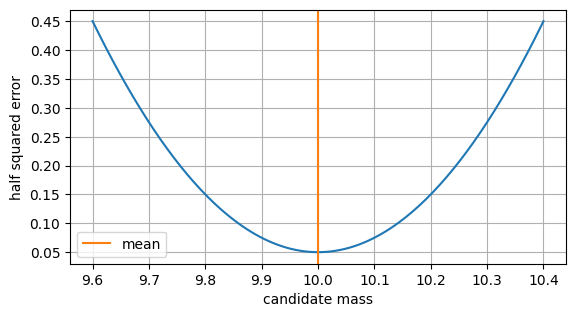

In [2]:
y = np.array([10.1, 9.9, 10.2, 10.0, 9.8])
grid = np.linspace(9.6, 10.4, 201)
loss = .5*np.sum((grid[:, None]-y)**2, axis=1)
print('mean:', y.mean(), 'minimum cost:', .5*np.sum((y-y.mean())**2))
assert np.isclose(y.mean(), 10.)
plt.plot(grid, loss); plt.axvline(y.mean(), color='C1', label='mean')
plt.xlabel('candidate mass'); plt.ylabel('half squared error'); plt.legend(); plt.show()

## 平方为什么既方便又危险

平方消除了正负抵消，平滑、容易求导；同时，大误差的惩罚增长很快。把一个读数错录为20，平均值会显著移动。若改为绝对误差和，最优解则是中位数。损失函数反映了我们怎样对待误差，不是数学强制要求平方在任何场景都正确。第12章将处理异常值。

## 从一个常数变成一条直线

现在测量时间$t_i$和位置$y_i$，假设$f_i(a,b)=a+bt_i$。未知量有截距$a$和斜率$b$。令两个偏导为零：

$$\sum_i(a+bt_i-y_i)=0,\qquad
\sum_i t_i(a+bt_i-y_i)=0.$$

当$t_i$不全相同时，解为

$$b=\frac{\sum_i(t_i-\bar t)(y_i-\bar y)}{\sum_i(t_i-\bar t)^2},\qquad a=\bar y-b\bar t.$$

直线必然经过$(\bar t,\bar y)$。注意：我们最小化的是竖直方向的观测误差，不是点到直线的垂直距离；这等价于把$t$当作足够准确的输入。

hand formula: [np.float64(1.2468646986979914), np.float64(1.9670997346181176)] NumPy: [1.24686 1.9671 ]


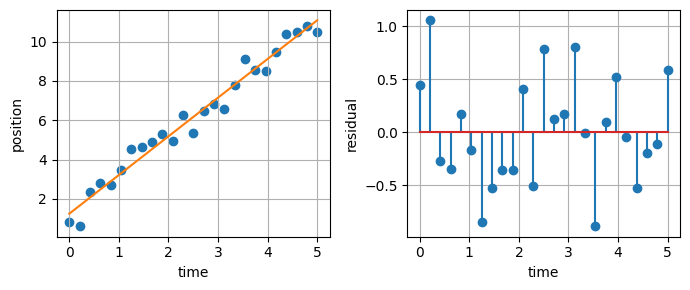

In [3]:
rng = np.random.default_rng(101)
t = np.linspace(0, 5, 25)
y = 1.2 + 2.0*t + rng.normal(0, .5, len(t))
b = np.sum((t-t.mean())*(y-y.mean())) / np.sum((t-t.mean())**2)
a = y.mean()-b*t.mean()
A = np.column_stack([np.ones_like(t), t])
reference = np.linalg.lstsq(A, y, rcond=None)[0]
print('hand formula:', [a, b], 'NumPy:', reference)
assert np.allclose([a, b], reference)
fig, ax = plt.subplots(1, 2, figsize=(7, 3))
ax[0].scatter(t, y); ax[0].plot(t, a+b*t, color='C1')
ax[0].set(xlabel='time', ylabel='position')
ax[1].stem(t, a+b*t-y); ax[1].set(xlabel='time', ylabel='residual')
plt.tight_layout(); plt.show()

## 如何阅读残差图

如果残差随时间弯曲，可能是直线模型遗漏了加速度；如果后半段波动明显增大，可能需要不同权重。一个很小的总误差并不能替代残差诊断。对含截距的普通线性最小二乘，残差之和应近似为零，这是可执行的自检。

## 练习与解答

1. 所有$y_i$加3，斜率和截距如何改变？解答：中心化后的$y_i-\bar y$不变，斜率不变，截距加3。
2. 把秒改为毫秒，斜率数值如何改变？解答：新时间是原来的1000倍，斜率为原来的$1/1000$，物理速度没有改变。
3. 将一个数据点增加8，观察斜率变化，再比较它位于时间区间中间和两端的情况。解答：两端点通常有更大的杠杆作用；异常值影响不仅由残差大小决定，还与输入位置有关。

本章结论：最小二乘给出的是在指定模型和误差定义下最一致的参数；它不能自动替你验证模型假设。